# 04 · Shorts Hook Rewriter: demo and evaluation

**Longevity Hook Lab, Part B**: *Can an LLM rewrite weak Shorts titles into versions the Part A model scores higher, without adding exaggerated health claims or changing what the video is about?*

How it works (`codes/hook_rewriter.py`):
1. One Gemini call turns a draft title into 5 rewrites, one per hook style (question, how-to, list, warning, story).
2. The Part A random forest scores the draft and each rewrite (P(beat)). Duration and posting time stay at the draft's values, so only the title changes.
3. Guardrails drop any rewrite that is over 70 characters, uses a banned hype phrase, adds hype words or numbers, uses more capitals, changes the topic, or changes the point of view (e.g. "she" becomes "I" or "you").
4. The best rewrite that passes is returned only if it scores higher than the draft. Otherwise the advice is to keep the draft.

Gemini replies are cached in `data/gemini_cache.json`, so re-running this notebook doesn't call the API again.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split

from features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, TEXT_FEATURE, add_features
from hook_rewriter import load_model, rewrite

DATA = Path("../data")
ASSETS = Path("../images")
RANDOM_STATE = 42

ACCENT = "#2a78d6"   # rewrite
SECOND = "#e07b39"   # draft
REF = "#8a8984"
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.max_colwidth", 80)

## 1. Five worked examples

Made-up drafts scored with the saved Part A model (`hook_model.joblib`), the same as running the script from the command line. Duration is set to 45 seconds.

In [2]:
saved_model = load_model()
examples = [
    ("Why you wake up at 3am every night", "sleep"),
    ("Magnesium and sleep quality", "supplements"),
    ("What happens to your brain when you stop drinking alcohol", "brain"),
    ("Walking after meals and blood sugar", "diet_fasting"),
    ("Strength training matters more as you get older", "exercise"),
]
demo = [rewrite(draft, topic, model=saved_model) for draft, topic in examples]
pd.DataFrame([{k: r[k] for k in ["draft", "draft_p_beat", "best_title", "best_p_beat", "uplift"]}
              | {"why": ", ".join(r["why"])} for r in demo])

,draft,draft_p_beat,best_title,best_p_beat,uplift,why
0,Why you wake up at 3am every night,0.453,How to stop waking up at 3am every night,0.525,0.072,"hook style: question -> how_to, - 'you'"
1,Magnesium and sleep quality,0.645,Magnesium and sleep quality,0.645,0.000,keep the draft: no safe rewrite scored higher
2,What happens to your brain when you stop drinking alcohol,0.603,Stop drinking alcohol to protect your brain health,0.703,0.100,hook style: question -> warning
3,Walking after meals and blood sugar,0.577,Walking after meals and blood sugar,0.577,0.000,keep the draft: no safe rewrite scored higher
4,Strength training matters more as you get older,0.445,How to prioritize strength training as you get older,0.578,0.133,hook style: other -> how_to


All five candidates for the first example, with the guardrail result for each:

In [3]:
demo[0]["candidates"]

,style,title,p_beat,passes,problems
1,how_to,How to stop waking up at 3am every night,0.525,True,
3,warning,Stop doing this if you wake up at 3am,0.507,True,
4,story,Why I wake up at 3am every night,0.492,False,point of view changed (added first person)
2,list,Why you wake up at 3am every night,0.453,True,
0,question,Why do you always wake up at 3am?,0.445,False,more hype words than draft


## 2. Evaluation on 30 weak titles from the Part A test set

**Which model scores the evaluation?** The saved model was refit on all 2,740 Shorts, test set included. A full-depth random forest memorises its training titles, so their original scores would come out artificially low while rewrites are scored as new titles. That would inflate the uplift. So for this evaluation I rebuild the exact Part A train/test split and refit the same tuned forest on the **training set only**. Every test title, original or rewritten, is then new to the model.

In [4]:
shorts = add_features(pd.read_csv("../data/shorts.csv"))
X = shorts[NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TEXT_FEATURE]]
y = shorts["beat"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

eval_model = clone(saved_model).fit(X_train, y_train)
test = shorts.loc[X_test.index].assign(p_beat=eval_model.predict_proba(X_test)[:, 1])
print("test set:", test.shape[0], "Shorts | test ROC-AUC check:",
      round(__import__("sklearn.metrics").metrics.roc_auc_score(y_test, test["p_beat"]), 3))

test set: 548 Shorts | test ROC-AUC check: 0.603


The 30 lowest-scoring test titles. Each one is rewritten with the topic given by the Part A keyword rules, and scored at its real duration and posting time.

In [5]:
weak = test.nsmallest(30, "p_beat")[["video_id", "creator", "title", "topic", "duration_sec", "published_at", "beat"]]
print(weak["creator"].value_counts().to_dict())
weak[["creator", "title", "topic"]].head()

{'Louisa Nicola': 7, 'Peter Attia': 6, 'Gary Brecka': 5, 'Bryan Johnson': 4, 'Gabrielle Lyon': 3, 'Andrew Huberman': 3, 'David Perlmutter': 1, 'Jessie Inchauspe': 1}


,creator,title,topic
907,Gabrielle Lyon,Bladder Damage,other
111,Bryan Johnson,Whether from Blueprint or somewhere else; make sure you consume EVOO every d...,other
1086,Gabrielle Lyon,The Autonomic Nervous System Data Nobody Is Talking About,other
281,Bryan Johnson,part 2: i traveled to London to talk about don't die,aging
2199,Peter Attia,#339 - Unpacking trauma: How early wounds shape behavior and the path toward...,other


In [6]:
rows = []
for _, s in weak.iterrows():
    r = rewrite(s["title"], s["topic"], duration_sec=s["duration_sec"],
                published_at=pd.Timestamp(s["published_at"]), model=eval_model)
    c = r["candidates"]
    rows.append({"video_id": s["video_id"], "creator": s["creator"], "topic": s["topic"],
                 "draft": r["draft"], "best_title": r["best_title"],
                 "draft_p_beat": r["draft_p_beat"], "best_p_beat": r["best_p_beat"], "uplift": r["uplift"],
                 "kept_draft": r["best_title"] == r["draft"], "why": ", ".join(r["why"]),
                 "n_passed": int(c["passes"].sum()), "problems": " | ".join(p for p in c["problems"] if p)})
results = pd.DataFrame(rows)
results[["draft", "best_title", "draft_p_beat", "best_p_beat"]].head(10)

,draft,best_title,draft_p_beat,best_p_beat
0,Bladder Damage,Stop doing this before it causes bladder damage,0.127,0.280
1,Whether from Blueprint or somewhere else; make sure you consume EVOO every d...,Stop skipping your daily dose of EVOO,0.127,0.452
2,The Autonomic Nervous System Data Nobody Is Talking About,Stop ignoring this autonomic nervous system data,0.137,0.182
3,part 2: i traveled to London to talk about don't die,Part 2 in London talking about don't die,0.142,0.228
4,#339 - Unpacking trauma: How early wounds shape behavior and the path toward...,Stop ignoring how early wounds shape behavior,0.152,0.262
5,YOUR NERVOUS SYSTEM IS STUCK IN SURVIVAL MODE,Stop letting your nervous system stay in survival mode,0.153,0.233
6,"AI in Medicine: The Top Two Priorities | Susan Desmond-Hellmann M.D., M.P.H",What are the top two priorities for AI in medicine?,0.168,0.342
7,"How to Access Calm, Confident Energy in You & Your Dog",Want calm energy for you and your dog?,0.170,0.442
8,"April 20, 2026","Do not miss April 20, 2026",0.175,0.383
9,She Was Healing Others While Destroying Herself | Madison Brecka,Was Madison Brecka healing others while destroying herself?,0.192,0.283


### 2.1 Score uplift

In [7]:
rewritten = results[~results["kept_draft"]]
summary = pd.Series({
    "titles evaluated": len(results),
    "rewrite scored higher (share)": round((results["uplift"] > 0).mean(), 2),
    "kept draft (no safe rewrite beat it)": int(results["kept_draft"].sum()),
    "mean uplift, all 30": round(results["uplift"].mean(), 3),
    "median uplift, all 30": round(results["uplift"].median(), 3),
    "mean P(beat) before": round(results["draft_p_beat"].mean(), 3),
    "mean P(beat) after": round(results["best_p_beat"].mean(), 3),
})
summary.to_frame("value")

,value
titles evaluated,30.000
rewrite scored higher (share),0.970
kept draft (no safe rewrite beat it),1.000
"mean uplift, all 30",0.159
"median uplift, all 30",0.146
mean P(beat) before,0.199
mean P(beat) after,0.358


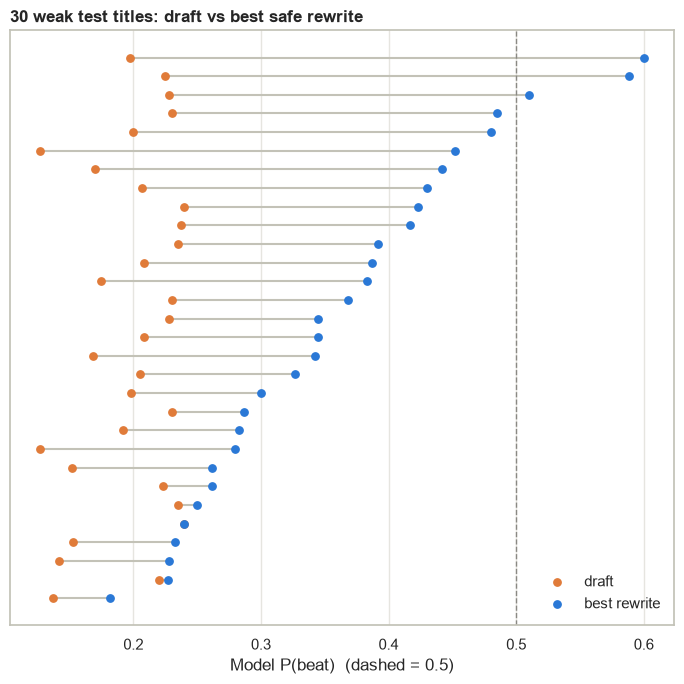

In [8]:
order = results.sort_values("best_p_beat").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 7))
for i, r in order.iterrows():
    ax.plot([r["draft_p_beat"], r["best_p_beat"]], [i, i], color="#c3c2b7", linewidth=1.5, zorder=1)
ax.scatter(order["draft_p_beat"], order.index, color=SECOND, s=28, label="draft", zorder=2)
ax.scatter(order["best_p_beat"], order.index, color=ACCENT, s=28, label="best rewrite", zorder=3)
ax.axvline(0.5, color=REF, linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_xlabel("Model P(beat)  (dashed = 0.5)")
ax.set_title("30 weak test titles: draft vs best safe rewrite", loc="left", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
fig.savefig(ASSETS / "uplift_dumbbell.png", dpi=150)
plt.show()

### 2.2 What the winning rewrites changed

Which hook style won most often, and how often each guardrail rejected a candidate (5 candidates × 30 titles = 150).

In [9]:
won_style = rewritten["why"].str.extract(r"hook style: \w+ -> (\w+)")[0].fillna("same style")
print("Winning hook style (when a rewrite won):", won_style.value_counts().to_dict())

reasons = (results["problems"].str.split(r" \| |; ").explode().str.replace(r"\s*\(.*|\s*'.*|\s*\[.*", "", regex=True)
           .str.strip().replace("", pd.NA).dropna())
print("Guardrail rejections:", reasons.value_counts().to_dict())
print("Candidates passing all guardrails:", results["n_passed"].sum(), "of", 5 * len(results))

Winning hook style (when a rewrite won): {'same style': 11, 'question': 7, 'warning': 6, 'how_to': 3, 'story': 1, 'other': 1}
Guardrail rejections: {'point of view changed': 24, 'more hype words than draft': 5, 'new number': 1, 'over 70 chars': 1}
Candidates passing all guardrails: 121 of 150


## 3. Faithfulness check (by hand)

A higher score is worthless if the rewrite changes the claim. `data/eval_rewrites.csv` lists each draft next to its best rewrite with an empty `faithful` column. Fill in **yes** (same meaning, no new claims or promises) or **no** for every row where the rewrite replaced the draft, then re-run this section. Answers already entered are kept when the notebook is re-run, as long as the rewrite next to them hasn't changed.

**Rule used:** a rewrite is faithful only if it adds no new claim, promise or topic, keeps the same speaker (no "she" → "I"), and a viewer would expect the same video. When in doubt, mark **no**.

In [10]:
EVAL_CSV = DATA / "eval_rewrites.csv"
out = results[["video_id", "creator", "draft", "best_title", "draft_p_beat", "best_p_beat", "uplift", "kept_draft", "why"]].copy()
if EVAL_CSV.exists():
    previous = pd.read_csv(EVAL_CSV)
    previous = previous[[c for c in ["video_id", "best_title", "faithful", "reason"] if c in previous]]
    out = out.merge(previous, on=["video_id", "best_title"], how="left")   # keep a rating only if the rewrite is unchanged
else:
    out["faithful"] = pd.NA
out.loc[out["kept_draft"], "faithful"] = "n/a (kept draft)"
out.to_csv(EVAL_CSV, index=False)

checked = out.loc[~out["kept_draft"], "faithful"].astype("string").str.strip().str.lower()
done = checked.isin(["yes", "no"])
if done.all() and len(checked):
    print(f"Faithful: {(checked == 'yes').mean():.0%} of {len(checked)} rewrites")
else:
    print(f"{(~done).sum()} of {len(checked)} rewrites still need a yes/no in {EVAL_CSV}")

Faithful: 62% of 29 rewrites


### 3.1 Before vs after the point-of-view fix

The first version of the rewriter (v1) scored only 34% faithful. Most failures were a **change of speaker**: many titles are about someone else (a guest, a patient, "she"), but the story hook was defined as first person, so Gemini turned them into "I"/"my". The final version tells Gemini to keep the draft's point of view, and adds a guardrail that rejects any rewrite that adds a kind of personal pronoun the draft doesn't use (I/we, you, she/he), or drops the person the draft is about ("she" → "you"). An in-between version that only blocked "I"/"my" wasn't enough: Gemini switched to "you" and invented "she"/"her" instead. v1 results are kept in `data/eval_rewrites_v1.csv`.

In [11]:
def summarise(df):
    changed = df[~df["kept_draft"]]
    rated = changed["faithful"].astype("string").str.strip().str.lower()
    return pd.Series({
        "rewrite scored higher": f"{(df['uplift'] > 0).sum()} of {len(df)}",
        "mean uplift": round(df["uplift"].mean(), 3),
        "faithful": f"{(rated == 'yes').sum()} of {len(changed)} ({(rated == 'yes').mean():.0%})"
                    if rated.isin(["yes", "no"]).all() else "not rated yet",
    })

pd.DataFrame({"v1 (before)": summarise(pd.read_csv(DATA / "eval_rewrites_v1.csv")),
              "after point-of-view fix": summarise(out)})

,v1 (before),after point-of-view fix
rewrite scored higher,29 of 30,29 of 30
mean uplift,0.215,0.159
faithful,10 of 29 (34%),18 of 29 (62%)


## 4. Caveats

- **The rewriter is trained to please the model, not viewers.** The Part A model has a test AUC of only 0.60, so a higher P(beat) is a weak hint, not a forecast of more views. The real check is an A/B test (YouTube's title test feature, or posting matched Shorts).
- **Gaming risk.** The forest leans on length, capitals and topic words. The capitals and topic guardrails stop the most obvious gaming, but rewrites can still win through wording that suits the model without being better for viewers.
- **Faithfulness is subtle.** "Why you wake up at 3am" → "How to stop waking up at 3am" passes every automatic rule but now implies a fix. That's why the hand check matters.
- **What the rules still miss.** After the point-of-view fix, the remaining unfaithful rewrites change the *meaning*: warning hooks that invent a cause ("Stop doing this before it causes bladder damage") or make a claim stronger ("could cause" → "is causing"). Catching these needs a human, or a second model that compares meanings.
- Weak drafts have room to improve (regression to the mean), so uplift on the 30 weakest titles overstates what an average title would gain.